## 1. Import Dependencies

In [38]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
from ydata_profiling import ProfileReport

%matplotlib inline


### load the dataset 

load data set and check the description

In [39]:
dataset = pd.read_csv('../data/All_three_combined.csv')

dataset.describe()

,Country Name,Country Code,Series Name,Series Code,2000 [YR2000],2001 [YR2001],2002 [YR2002],2003 [YR2003],2004 [YR2004],2005 [YR2005],...,2015 [YR2015],2016 [YR2016],2017 [YR2017],2018 [YR2018],2019 [YR2019],2020 [YR2020],2021 [YR2021],2022 [YR2022],2023 [YR2023],2024 [YR2024]
count,798,798,798,798,798,798,798,798,798,798,...,798,798,798,798,798,798,798,798,798,798
unique,266,266,3,3,655,661,659,660,660,680,...,668,676,673,671,686,668,670,670,643,634
top,Afghanistan,AFG,GDP per capita (current US$),NY.GDP.PCAP.CD,..,..,..,..,..,..,...,..,..,..,..,..,..,..,..,..,..
freq,3,3,266,266,138,130,134,133,132,110,...,121,117,120,122,105,124,122,122,150,160


#### Generate a data overview report for the combined dataset

In [40]:
# report = ProfileReport(dataset, title="Pandas Profiling Report", explorative=True)
# report.to_file("../reports/gdp_per_capita_report.html")

## 2. Question 1: How are GDP per capita, unemployment, and life expectancy related across countries from 2000 to 2024?

Plan:
1. Reshape the data into one row per country-year and drop regional aggregates.
2. Check data coverage and distributions.
3. Look at trends over time.
4. Examine each pairwise relationship (scatter plots, correlations).
5. Check whether the relationships are stable over time and whether income growth goes with improvements.

In [41]:
# Reshape from World Bank format (one row per country x indicator, one column per year)
# to a tidy table with one row per country-year and one column per indicator.
year_cols = [c for c in dataset.columns if '[YR' in c]
long = dataset.dropna(subset=['Series Code']).melt(
    id_vars=['Country Name', 'Country Code', 'Series Code'],
    value_vars=year_cols, var_name='year', value_name='value')

long['year'] = long['year'].str[:4].astype(int)                             # "2000 [YR2000]" -> 2000
long['value'] = pd.to_numeric(long['value'].replace('..', np.nan), errors='coerce')  # ".." means missing
long['indicator'] = long['Series Code'].map({
    'NY.GDP.PCAP.CD': 'gdp_per_capita',
    'SP.DYN.LE00.IN': 'life_expectancy',
    'SL.UEM.TOTL.NE.ZS': 'unemployment_rate'})

df = (long.set_index(['Country Name', 'Country Code', 'year', 'indicator'])['value']
          .unstack('indicator').reset_index())

# The file also contains regional/income-group aggregates (World, Euro area, ...).
# They would double count countries, so drop them.
aggregate_codes = {
    'AFE', 'AFW', 'ARB', 'CEB', 'CSS', 'EAP', 'EAR', 'EAS', 'ECA', 'ECS', 'EMU', 'EUU',
    'FCS', 'HIC', 'HPC', 'IBD', 'IBT', 'IDA', 'IDB', 'IDX', 'INX', 'LAC', 'LCN', 'LDC',
    'LIC', 'LMC', 'LMY', 'LTE', 'MEA', 'MIC', 'MNA', 'NAC', 'OED', 'OSS', 'PRE', 'PSS',
    'PST', 'SAS', 'SSA', 'SSF', 'SST', 'TEA', 'TEC', 'TLA', 'TMN', 'TSA', 'TSS', 'UMC', 'WLD'}
df = df[~df['Country Code'].isin(aggregate_codes)].copy()

df['log_gdp'] = np.log10(df['gdp_per_capita'])   # GDP is highly skewed, so analyse it on a log scale
df.head()

indicator,Country Name,Country Code,year,gdp_per_capita,life_expectancy,unemployment_rate,log_gdp
0,Afghanistan,AFG,2000,174.930991,55.005,NaN,2.242867
1,Afghanistan,AFG,2001,138.706822,55.511,NaN,2.142098
2,Afghanistan,AFG,2002,178.954088,56.225,NaN,2.252742
3,Afghanistan,AFG,2003,198.871116,57.171,NaN,2.298572
4,Afghanistan,AFG,2004,221.763654,57.810,NaN,2.345890


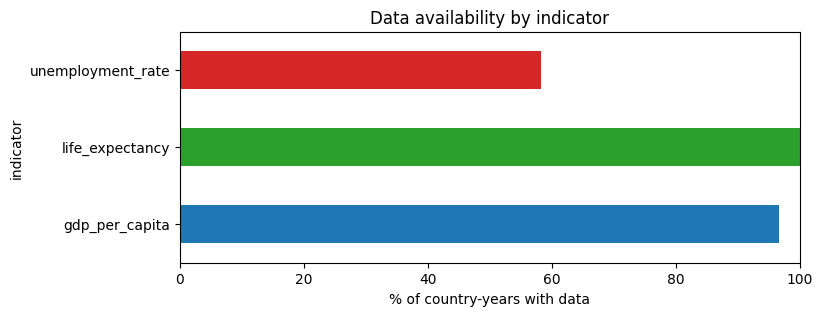

Countries in data: 218
Country-years with all three indicators: 3160 (207 countries)


In [42]:
# Data coverage: share of country-year cells that actually have a value.
# Unemployment is much sparser than the other two, which limits any comparison involving it.
indicator_cols = ['gdp_per_capita', 'life_expectancy', 'unemployment_rate']
coverage = df[indicator_cols].notna().mean().mul(100).round(1)

ax = coverage.plot.barh(color=['tab:blue', 'tab:green', 'tab:red'], figsize=(8, 3))
ax.set_xlim(0, 100)
ax.set_xlabel('% of country-years with data')
ax.set_title('Data availability by indicator')
plt.show()

complete = df.dropna(subset=indicator_cols)
print(f'Countries in data: {df["Country Name"].nunique()}')
print(f'Country-years with all three indicators: {len(complete)} '
      f'({complete["Country Name"].nunique()} countries)')

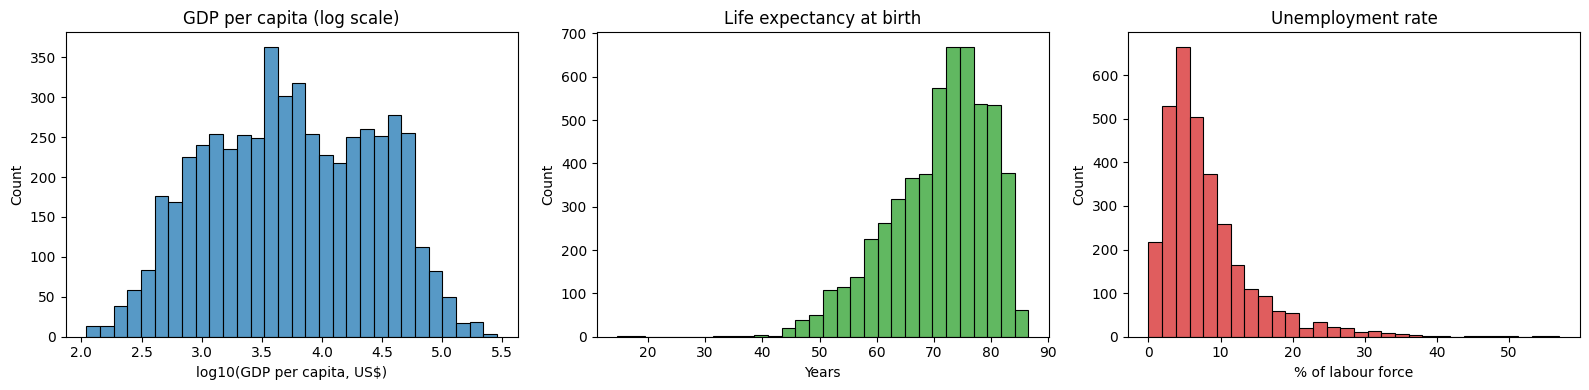

indicator,gdp_per_capita,life_expectancy,unemployment_rate
count,5267.00,5450.00,3177.00
mean,16245.17,70.97,8.05
std,25434.70,8.76,6.35
min,109.59,14.66,0.00
25%,1574.98,65.46,3.94
50%,5408.05,72.64,6.37
75%,21056.07,77.54,10.15
max,288001.57,86.50,57.00


In [43]:
# Distribution of each indicator across all country-years.
# GDP per capita is very right-skewed, so it is shown on a log10 scale.
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(df['log_gdp'].dropna(), bins=30, ax=axes[0], color='tab:blue')
axes[0].set_xlabel('log10(GDP per capita, US$)')
axes[0].set_title('GDP per capita (log scale)')

sns.histplot(df['life_expectancy'].dropna(), bins=30, ax=axes[1], color='tab:green')
axes[1].set_xlabel('Years')
axes[1].set_title('Life expectancy at birth')

sns.histplot(df['unemployment_rate'].dropna(), bins=30, ax=axes[2], color='tab:red')
axes[2].set_xlabel('% of labour force')
axes[2].set_title('Unemployment rate')

plt.tight_layout()
plt.show()

df[['gdp_per_capita', 'life_expectancy', 'unemployment_rate']].describe().round(2)

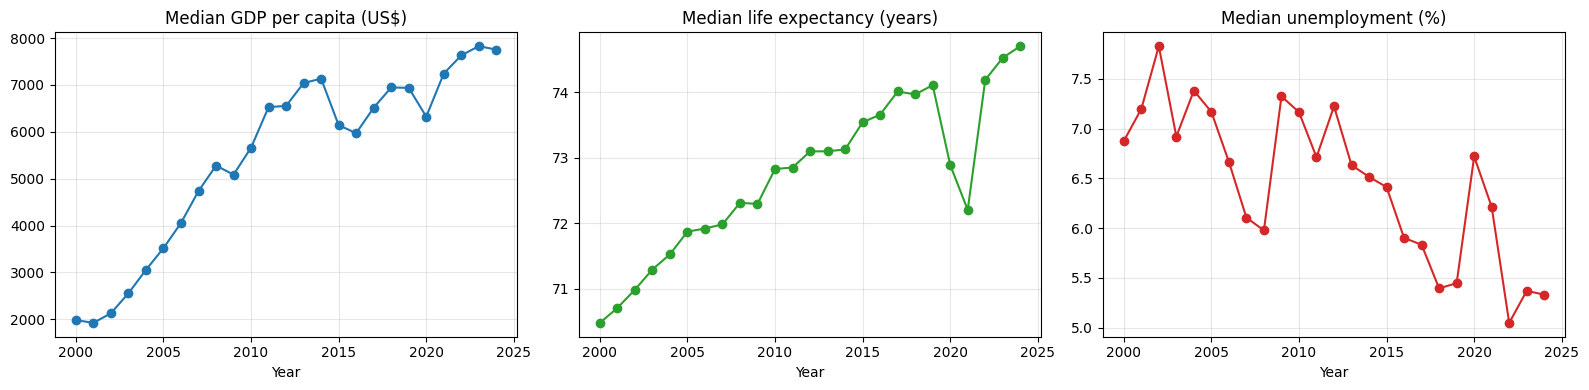

In [44]:
# How have the three indicators moved over time? Median across countries per year
# (median, not mean, so very rich or very poor countries do not dominate).
yearly_median = df.groupby('year')[['gdp_per_capita', 'life_expectancy', 'unemployment_rate']].median()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
titles = ['Median GDP per capita (US$)', 'Median life expectancy (years)', 'Median unemployment (%)']
colors = ['tab:blue', 'tab:green', 'tab:red']
for ax, col, title, color in zip(axes, yearly_median.columns, titles, colors):
    ax.plot(yearly_median.index, yearly_median[col], marker='o', color=color)
    ax.set_title(title)
    ax.set_xlabel('Year')
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

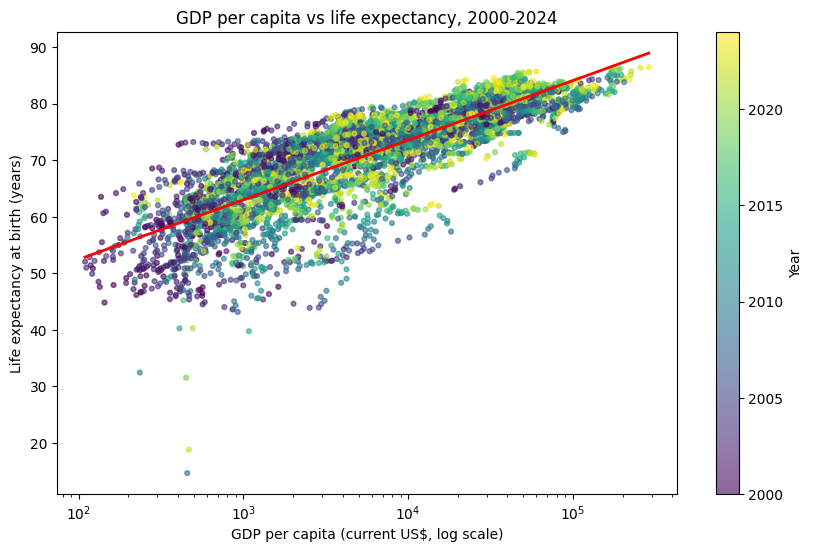

Each 10x increase in GDP per capita is associated with about 10.5 more years of life expectancy.


In [45]:
# Core relationship: GDP per capita vs life expectancy.
# The x-axis is logarithmic because income spans several orders of magnitude.
# Colour shows the year, so upward drift over time is visible too.
def add_trend(ax, x, y, log_x=False, color='red'):
    """Draw a least-squares line (fitted on log10(x) if log_x) and return its slope."""
    m = x.notna() & y.notna()
    xv = np.log10(x[m]) if log_x else x[m]
    slope, intercept = np.polyfit(xv, y[m], 1)
    xs = np.linspace(xv.min(), xv.max(), 100)
    ax.plot(10 ** xs if log_x else xs, slope * xs + intercept, color=color, lw=2)
    return slope

fig, ax = plt.subplots(figsize=(10, 6))
sc = ax.scatter(df['gdp_per_capita'], df['life_expectancy'],
                c=df['year'], cmap='viridis', s=12, alpha=0.6)
ax.set_xscale('log')
slope = add_trend(ax, df['gdp_per_capita'], df['life_expectancy'], log_x=True)
plt.colorbar(sc, label='Year')
ax.set_xlabel('GDP per capita (current US$, log scale)')
ax.set_ylabel('Life expectancy at birth (years)')
ax.set_title('GDP per capita vs life expectancy, 2000-2024')
plt.show()

print(f'Each 10x increase in GDP per capita is associated with about {slope:.1f} more years of life expectancy.')

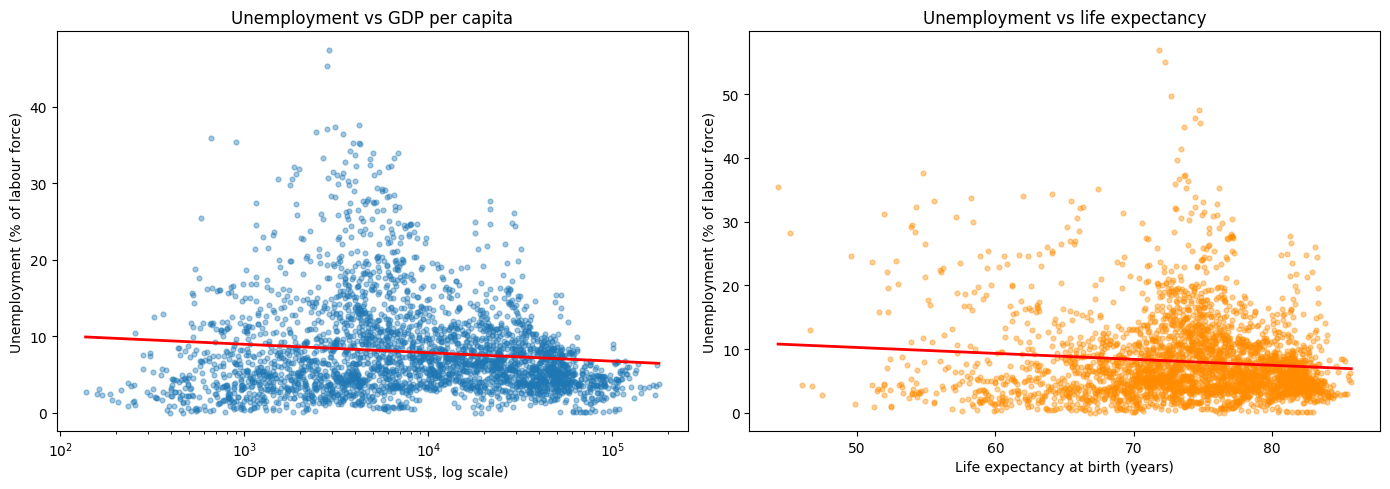

In [46]:
# Unemployment against the other two indicators (each point is one country-year).
# Unemployment is "national estimate", so definitions differ between countries.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(df['gdp_per_capita'], df['unemployment_rate'], s=12, alpha=0.4)
axes[0].set_xscale('log')
add_trend(axes[0], df['gdp_per_capita'], df['unemployment_rate'], log_x=True)
axes[0].set_xlabel('GDP per capita (current US$, log scale)')
axes[0].set_ylabel('Unemployment (% of labour force)')
axes[0].set_title('Unemployment vs GDP per capita')

axes[1].scatter(df['life_expectancy'], df['unemployment_rate'], s=12, alpha=0.4, color='darkorange')
add_trend(axes[1], df['life_expectancy'], df['unemployment_rate'])
axes[1].set_xlabel('Life expectancy at birth (years)')
axes[1].set_ylabel('Unemployment (% of labour force)')
axes[1].set_title('Unemployment vs life expectancy')

plt.tight_layout()
plt.show()

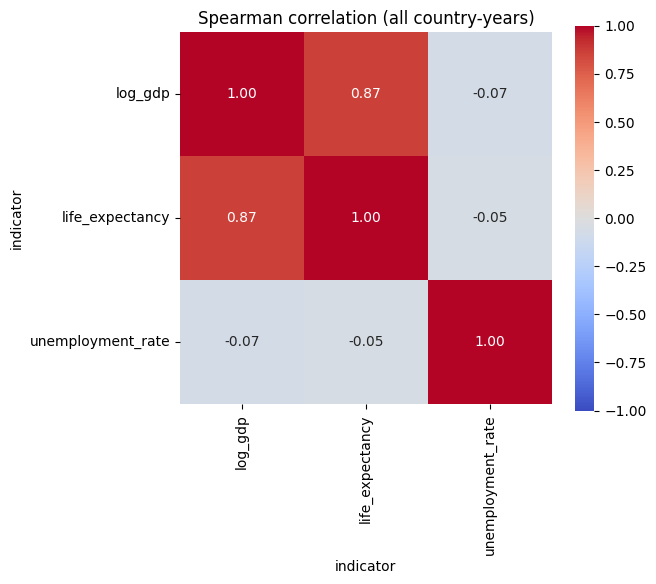

In [47]:
# Correlation heatmap across all country-year observations.
# Spearman (rank-based) is used because GDP is heavily skewed and the relationships are not linear.
# log_gdp is used so rank order is the same but the labels are on the scale of the scatter plots.
corr_cols = ['log_gdp', 'life_expectancy', 'unemployment_rate']
corr = df[corr_cols].corr(method='spearman')

plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True)
plt.title('Spearman correlation (all country-years)')
plt.show()

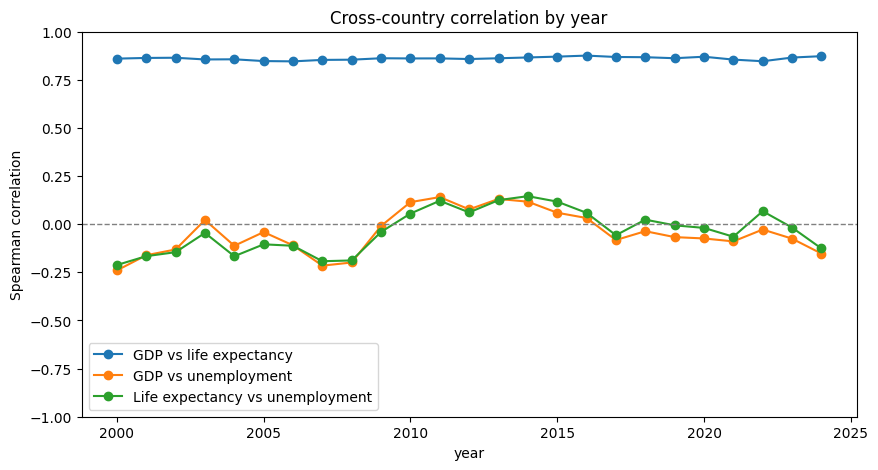

In [48]:
# Is the relationship stable over time? Recompute the Spearman correlation separately
# for every year and plot it. Flat lines mean the link did not change between 2000 and 2024.
pairs = [('log_gdp', 'life_expectancy', 'GDP vs life expectancy'),
         ('log_gdp', 'unemployment_rate', 'GDP vs unemployment'),
         ('life_expectancy', 'unemployment_rate', 'Life expectancy vs unemployment')]

yearly = {}
for a, b, label in pairs:
    yearly[label] = df.groupby('year').apply(
        lambda g: g[a].corr(g[b], method='spearman'), include_groups=False)
yearly = pd.DataFrame(yearly)

ax = yearly.plot(marker='o', figsize=(10, 5))
ax.axhline(0, color='grey', lw=1, ls='--')
ax.set_ylim(-1, 1)
ax.set_ylabel('Spearman correlation')
ax.set_title('Cross-country correlation by year')
plt.show()

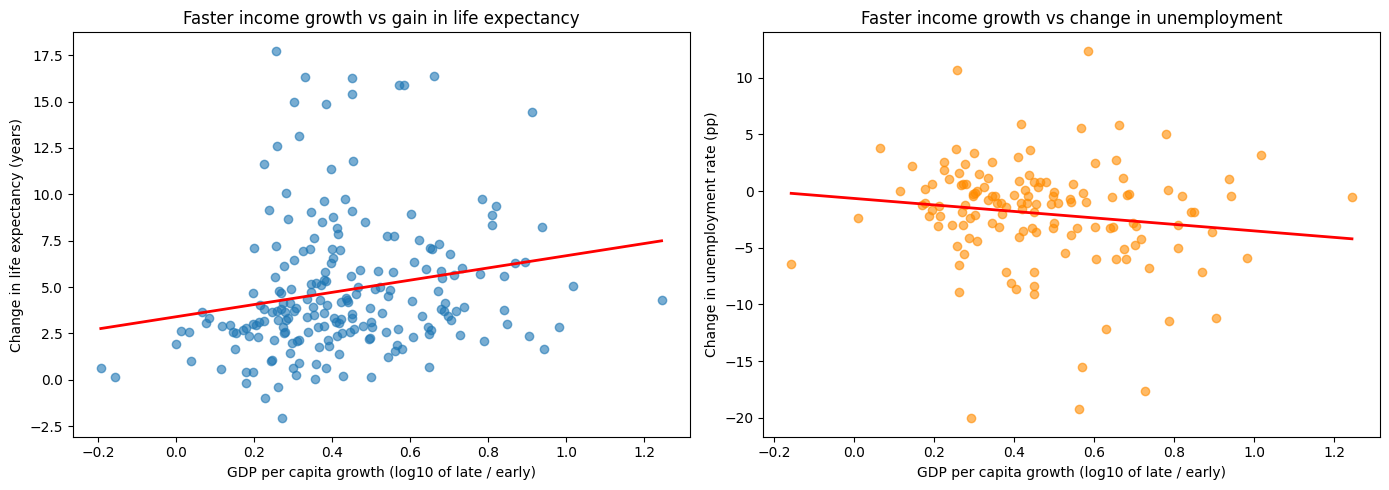

                  gdp_growth_log10  life_exp_change  unemp_change
gdp_growth_log10             1.000            0.278        -0.180
life_exp_change              0.278            1.000         0.194
unemp_change                -0.180            0.194         1.000


In [49]:
# Do countries that grew richer also improve? Compare the early period (2000-2004)
# with the late period (2020-2024). Averaging 5 years smooths gaps and one-off shocks.
value_cols = ['gdp_per_capita', 'life_expectancy', 'unemployment_rate']
early = df[df['year'].between(2000, 2004)].groupby('Country Name')[value_cols].mean()
late = df[df['year'].between(2020, 2024)].groupby('Country Name')[value_cols].mean()

change = pd.DataFrame({
    'gdp_growth_log10': np.log10(late['gdp_per_capita'] / early['gdp_per_capita']),
    'life_exp_change': late['life_expectancy'] - early['life_expectancy'],
    'unemp_change': late['unemployment_rate'] - early['unemployment_rate'],
})

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(change['gdp_growth_log10'], change['life_exp_change'], alpha=0.6)
add_trend(axes[0], change['gdp_growth_log10'], change['life_exp_change'])
axes[0].set_xlabel('GDP per capita growth (log10 of late / early)')
axes[0].set_ylabel('Change in life expectancy (years)')
axes[0].set_title('Faster income growth vs gain in life expectancy')

axes[1].scatter(change['gdp_growth_log10'], change['unemp_change'], alpha=0.6, color='darkorange')
add_trend(axes[1], change['gdp_growth_log10'], change['unemp_change'])
axes[1].set_xlabel('GDP per capita growth (log10 of late / early)')
axes[1].set_ylabel('Change in unemployment rate (pp)')
axes[1].set_title('Faster income growth vs change in unemployment')

plt.tight_layout()
plt.show()

print(change.corr(method='spearman').round(3))

In [50]:
# Summary table: Spearman correlation for each pair of indicators,
# using (a) every country-year observation and (b) each country's 2000-2024 average.
# Comparing the two shows whether the relationship is driven by differences between countries.
cols = ['log_gdp', 'life_expectancy', 'unemployment_rate']
country_avg = df.groupby('Country Name')[cols].mean()

pairs = [('log_gdp', 'life_expectancy'),
         ('log_gdp', 'unemployment_rate'),
         ('life_expectancy', 'unemployment_rate')]

rows = []
for a, b in pairs:
    for label, data in [('All country-years', df), ('Country averages', country_avg)]:
        valid = data[[a, b]].dropna()
        rows.append({'pair': f'{a} vs {b}',
                     'sample': label,
                     'n': len(valid),
                     'spearman': valid[a].corr(valid[b], method='spearman')})

summary = pd.DataFrame(rows).round(3)
summary

,pair,sample,n,spearman
0,log_gdp vs life_expectancy,All country-years,5267,0.866
1,log_gdp vs life_expectancy,Country averages,215,0.872
2,log_gdp vs unemployment_rate,All country-years,3160,-0.072
3,log_gdp vs unemployment_rate,Country averages,207,0.083
4,life_expectancy vs unemployment_rate,All country-years,3177,-0.048
5,life_expectancy vs unemployment_rate,Country averages,207,0.010


### Reading the results

- **GDP per capita vs life expectancy**: check the log-scale scatter and the Spearman correlations above. A strong positive relationship with diminishing returns at high income is the typical pattern (the Preston curve): richer countries live longer, but each extra dollar adds less at the top.
- **Unemployment vs the other two**: unemployment is measured on national definitions and is sparsely reported, so expect a much weaker and noisier link. Compare the pooled and country-average correlations before drawing conclusions.
- **Over time**: the per-year correlation plot shows whether the GDP-life expectancy link is stable across 2000-2024. The change plots show whether countries that grew faster also gained more years of life.
- **Caveats**: correlation is not causation (health also drives productivity), GDP per capita is in current US$ (not inflation or PPP adjusted), and missing values mean the countries compared differ slightly from one analysis to the next.

## 3. Question 2: Do countries with higher GDP per capita tend to have lower unemployment rates?

Approach:
1. Compare countries directly using their 2000-2024 averages (scatter plot, correlation).
2. Test whether the correlation could be due to chance (permutation test).
3. Compare unemployment across income groups.
4. Check whether the pattern holds in individual years.
5. Check whether unemployment falls as an individual country gets richer.

This reuses `df` and `add_trend` from Question 1, so run those cells first.

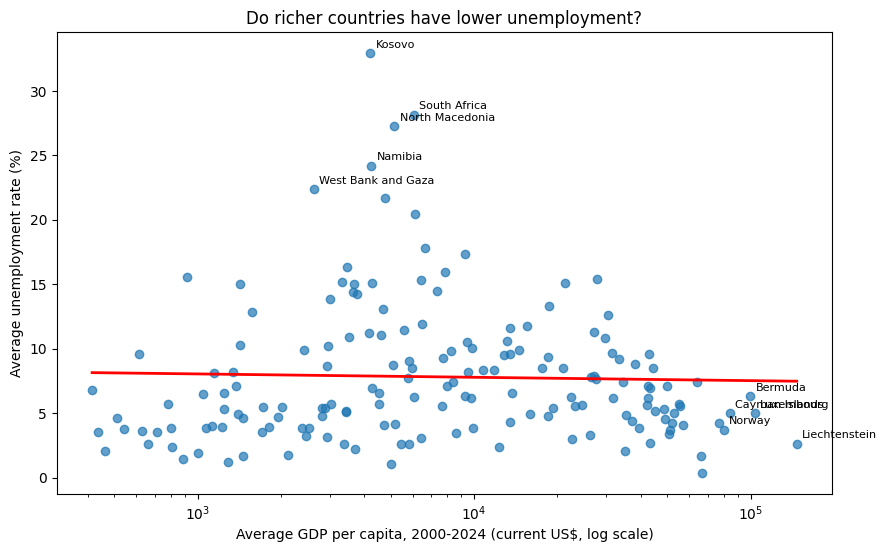

Countries: 170
Spearman = 0.049, Pearson (on log GDP) = -0.030
A 10x higher GDP per capita goes with -0.26 percentage points of unemployment.


In [51]:
# One point per country: average GDP per capita and average unemployment over 2000-2024.
# Averaging removes year-to-year noise and gives each country equal weight.
# Countries with fewer than 5 years of unemployment data are dropped so averages are not based on one year.
n_unemp = df.groupby('Country Name')['unemployment_rate'].count().rename('n_unemp')
avg = (df.groupby('Country Name')
         .agg(gdp_per_capita=('gdp_per_capita', 'mean'),
              unemployment_rate=('unemployment_rate', 'mean'))
         .join(n_unemp))
avg = avg[avg['n_unemp'] >= 5].dropna(subset=['gdp_per_capita', 'unemployment_rate']).copy()
avg['log_gdp'] = np.log10(avg['gdp_per_capita'])

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(avg['gdp_per_capita'], avg['unemployment_rate'], alpha=0.7)
ax.set_xscale('log')
slope = add_trend(ax, avg['gdp_per_capita'], avg['unemployment_rate'], log_x=True)

# Label the most extreme countries so outliers are identifiable
for name in set(avg['unemployment_rate'].nlargest(5).index) | set(avg['gdp_per_capita'].nlargest(5).index):
    r = avg.loc[name]
    ax.annotate(name, (r['gdp_per_capita'], r['unemployment_rate']), fontsize=8,
                xytext=(4, 4), textcoords='offset points')

ax.set_xlabel('Average GDP per capita, 2000-2024 (current US$, log scale)')
ax.set_ylabel('Average unemployment rate (%)')
ax.set_title('Do richer countries have lower unemployment?')
plt.show()

spearman = avg['log_gdp'].corr(avg['unemployment_rate'], method='spearman')
pearson = avg['log_gdp'].corr(avg['unemployment_rate'])
print(f'Countries: {len(avg)}')
print(f'Spearman = {spearman:.3f}, Pearson (on log GDP) = {pearson:.3f}')
print(f'A 10x higher GDP per capita goes with {slope:+.2f} percentage points of unemployment.')

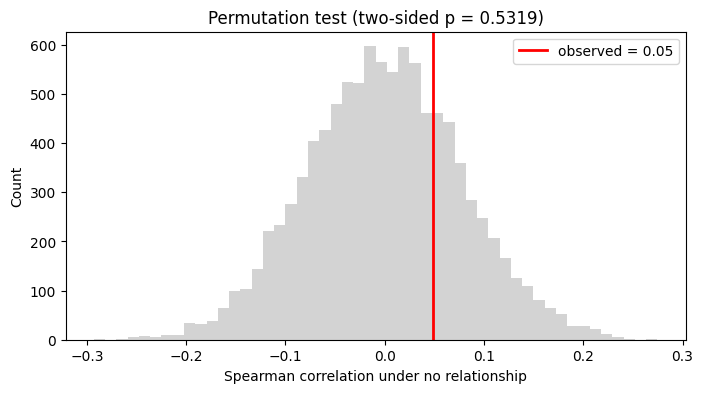

In [52]:
# Permutation test: how likely is a correlation this strong if GDP and unemployment were
# unrelated? Shuffle the unemployment ranks 10,000 times and compare with the observed value.
rng = np.random.default_rng(42)
observed = avg['log_gdp'].corr(avg['unemployment_rate'], method='spearman')

rank_x = avg['log_gdp'].rank().to_numpy()
rank_y = avg['unemployment_rate'].rank().to_numpy()
null = np.array([np.corrcoef(rank_x, rng.permutation(rank_y))[0, 1] for _ in range(10_000)])
p_value = (np.abs(null) >= abs(observed)).mean()

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(null, bins=50, color='lightgrey')
ax.axvline(observed, color='red', lw=2, label=f'observed = {observed:.2f}')
ax.set_xlabel('Spearman correlation under no relationship')
ax.set_ylabel('Count')
ax.set_title(f'Permutation test (two-sided p = {p_value:.4f})')
ax.legend()
plt.show()

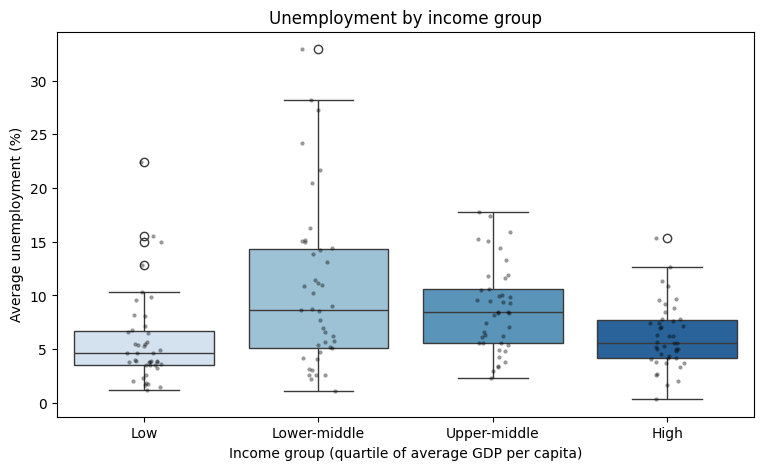

,count,median,mean
income_group,,,
Low,43,4.60,5.78
Lower-middle,42,8.69,10.63
Upper-middle,42,8.43,8.74
High,43,5.59,6.19


In [53]:
# Group countries into four income quartiles (by average GDP per capita) and compare their
# unemployment. This is easier to read than a scatter if the relationship is not a straight line.
avg['income_group'] = pd.qcut(avg['gdp_per_capita'], 4,
                              labels=['Low', 'Lower-middle', 'Upper-middle', 'High'])

fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=avg, x='income_group', y='unemployment_rate',
            hue='income_group', legend=False, palette='Blues', ax=ax)
sns.stripplot(data=avg, x='income_group', y='unemployment_rate', color='black', alpha=0.4, size=3, ax=ax)
ax.set_xlabel('Income group (quartile of average GDP per capita)')
ax.set_ylabel('Average unemployment (%)')
ax.set_title('Unemployment by income group')
plt.show()

avg.groupby('income_group', observed=True)['unemployment_rate'].agg(['count', 'median', 'mean']).round(2)

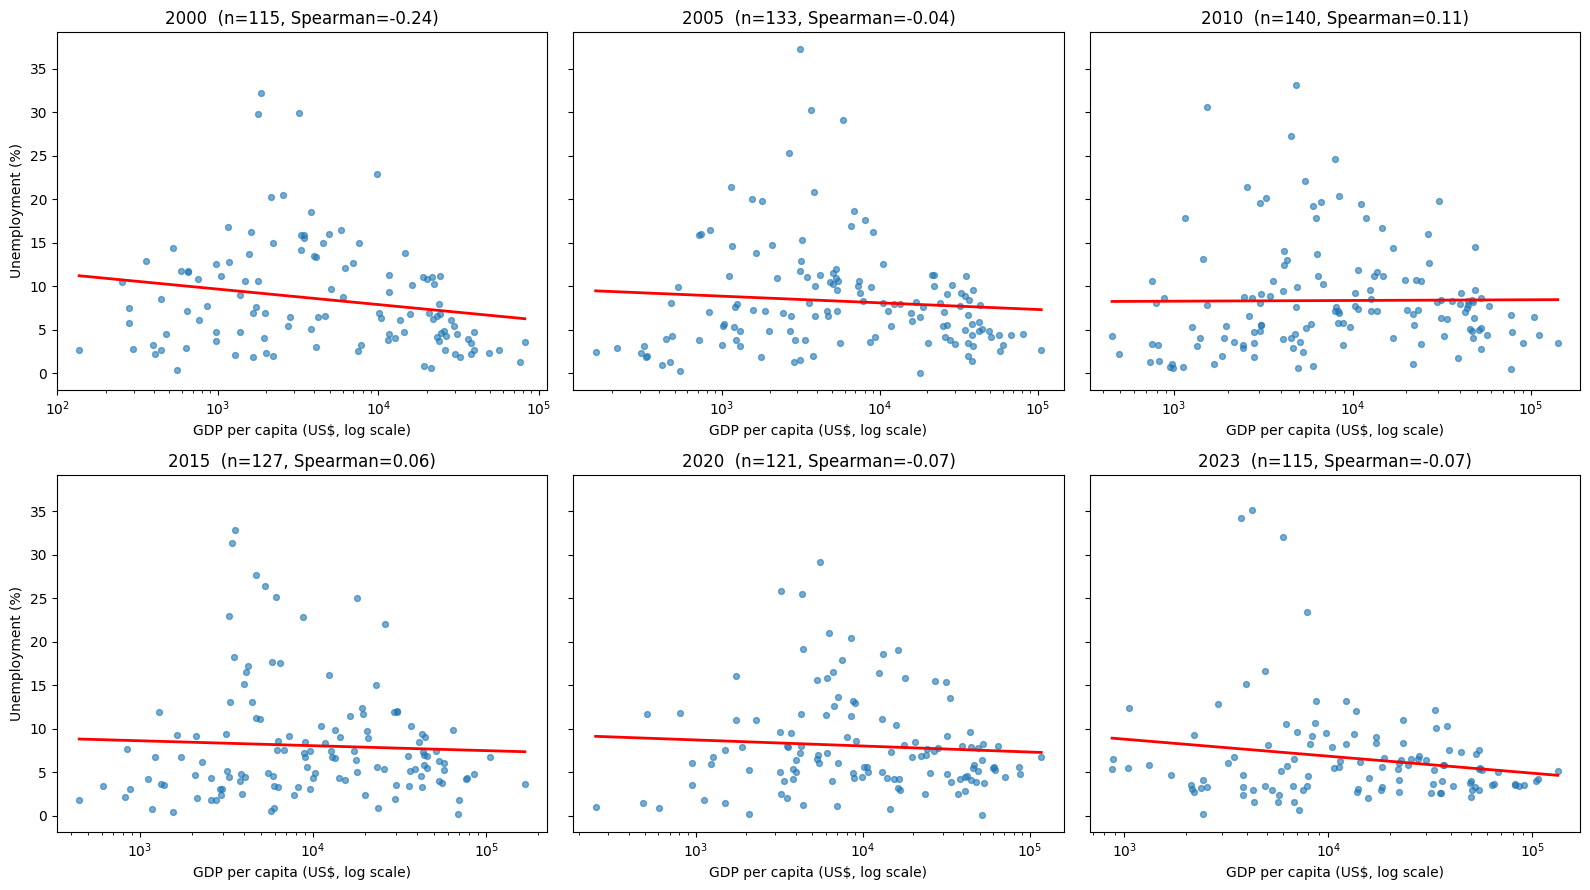

In [54]:
# Is the pattern the same in individual years? One panel per year, each with its own
# trend line and Spearman correlation. Years are spread across the period, including 2009/2020 shocks.
years = [2000, 2005, 2010, 2015, 2020, 2023]
fig, axes = plt.subplots(2, 3, figsize=(16, 9), sharey=True)

for ax, yr in zip(axes.ravel(), years):
    d = df[df['year'] == yr].dropna(subset=['gdp_per_capita', 'unemployment_rate'])
    ax.scatter(d['gdp_per_capita'], d['unemployment_rate'], s=18, alpha=0.6)
    ax.set_xscale('log')
    add_trend(ax, d['gdp_per_capita'], d['unemployment_rate'], log_x=True)
    rho = d['log_gdp'].corr(d['unemployment_rate'], method='spearman')
    ax.set_title(f'{yr}  (n={len(d)}, Spearman={rho:.2f})')
    ax.set_xlabel('GDP per capita (US$, log scale)')
axes[0, 0].set_ylabel('Unemployment (%)')
axes[1, 0].set_ylabel('Unemployment (%)')
plt.tight_layout()
plt.show()

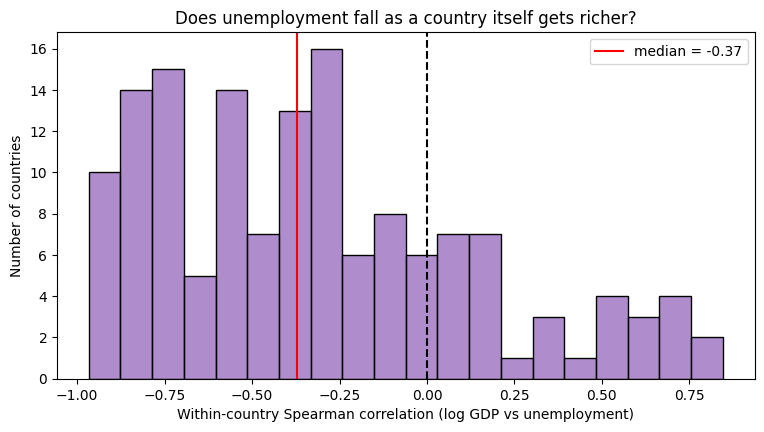

146 countries; 76% have a negative correlation, 24% positive.


In [55]:
# Within-country view: for each country, correlate its own GDP per capita with its own
# unemployment over time. A negative value means unemployment was lower in its richer years.
# Only countries with at least 8 years of data are used.
def within_corr(g):
    g = g.dropna(subset=['log_gdp', 'unemployment_rate'])
    if len(g) < 8:
        return np.nan
    return g['log_gdp'].corr(g['unemployment_rate'], method='spearman')

within = df.groupby('Country Name').apply(within_corr, include_groups=False).dropna()

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(within, bins=20, ax=ax, color='tab:purple')
ax.axvline(0, color='black', ls='--')
ax.axvline(within.median(), color='red', label=f'median = {within.median():.2f}')
ax.set_xlabel('Within-country Spearman correlation (log GDP vs unemployment)')
ax.set_ylabel('Number of countries')
ax.set_title('Does unemployment fall as a country itself gets richer?')
ax.legend()
plt.show()

print(f'{len(within)} countries; {(within < 0).mean():.0%} have a negative correlation, '
      f'{(within > 0).mean():.0%} positive.')

### Reading the results (Question 2)

- **Between countries**: read the country-average scatter, the Spearman value and the permutation p-value together. A small or insignificant correlation, and overlapping income-group boxes, mean richer countries do *not* reliably have lower unemployment.
- **Over time**: if the per-year panels show a similar weak slope in every year, the answer does not depend on which year you pick.
- **Within countries**: the share of countries with a negative correlation tells you whether a country's unemployment tends to fall as its own GDP per capita rises. Because GDP is in current US$, much of that growth is inflation and exchange-rate movement, so treat this as a rough signal only.
- **Why the link can be weak**: unemployment is a short-run, cyclical measure that depends on labour-market institutions, informal work and how it is measured, while GDP per capita reflects long-run productivity. Poor countries often report low open unemployment because most people cannot afford to be unemployed and work informally.
- **Caveats**: unemployment is sparsely reported (see the coverage chart), definitions are national estimates, and only countries with enough observations are included.